# Sieci Kohonena - porównanie

In [26]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from collections import Counter
from plotly.subplots import make_subplots
import itertools
from sklearn.datasets import fetch_openml
import seaborn as sns

In [27]:
def funkcja_wygaszajaca(t, wygaszanie):
    return np.exp(- t / wygaszanie)

def funkcja_Gaussa(d2_grid, sigma):
    return np.exp(-d2_grid / (2 * sigma**2))

def meksykanski_kapelusz(d2_grid, sigma):
    val = -d2_grid / (sigma**2)
    return (1 + val) * np.exp(val / 2)

def ij_to_xy(i, j):
    x = j + 0.5 * (i % 2)
    y = i * (np.sqrt(3) / 2)
    return x, y

In [28]:
class Kohonen:
    def __init__(self, M, N, len_wejscia, iteracje, sigma, funkcja_sasiedztwa, wygaszanie, topologia):
        self.M = M
        self.N = N
        self.len_wejscia = len_wejscia
        self.iteracje = iteracje
        self.sigma = sigma
        self.wagi = None
        self.funkcja_sasiedztwa = funkcja_sasiedztwa
        self.wygaszanie = wygaszanie
        self.min_vals = 0
        self.max_vals = 1
        self.topologia = topologia

    def znajdz_najblizszy(self, x):
        # odległość euklidesowa
        odleglosci = np.linalg.norm(self.wagi - x, axis=-1)
        min_idx = np.argmin(odleglosci)
        return np.unravel_index(min_idx, (self.M, self.N))
    
    def update(self, x, best_coord, alpha):
        i_grid, j_grid = np.indices((self.M, self.N))

        if self.topologia == 'szesciokat':
            x_grid, y_grid = ij_to_xy(i_grid, j_grid)
            best_x, best_y = ij_to_xy(best_coord[0], best_coord[1])
            d2_grid = (x_grid - best_x)**2 + (y_grid - best_y)**2
            
        else:
            d2_grid = (i_grid - best_coord[0])**2 + (j_grid - best_coord[1])**2

        theta = self.funkcja_sasiedztwa(d2_grid, self.sigma)
        theta = theta[..., np.newaxis]
        self.wagi += theta * alpha * (x - self.wagi)
        self.wagi = np.clip(self.wagi, self.min_vals, self.max_vals)

    def train(self, data):
        liczba_probek = data.shape[0]

        self.min_vals = np.min(data, axis=0) 
        self.max_vals = np.max(data, axis=0)
        self.wagi = np.random.uniform(self.min_vals, self.max_vals, (self.M, self.N, self.len_wejscia))

        for t in range(self.iteracje):
            alpha = funkcja_wygaszajaca(t, self.wygaszanie)

            indeksy = np.arange(liczba_probek)
            np.random.shuffle(indeksy)
          
            for idx in indeksy:
                x = data[idx] 
                best_coord = self.znajdz_najblizszy(x)
                self.update(x, best_coord, alpha)

In [29]:
def to_one_hot(y, liczba_klas):
    m = np.zeros((len(y), liczba_klas))
    m[np.arange(len(y)), y.flatten()] = 1
    return m

In [30]:
def train_grid(data, y_etykiety, n, NM_lista, sigma_gauss_lista, sigma_mexican_lista, f_gauss, f_mexican, topologie_lista, epoki=10, wygaszanie=5):
    df_dane = []

    kombinacje_gauss = list(itertools.product([f_gauss], sigma_gauss_lista, NM_lista, topologie_lista))
    kombinacje_mexican = list(itertools.product([f_mexican], sigma_mexican_lista, NM_lista, topologie_lista))
    
    kombinacje = kombinacje_gauss + kombinacje_mexican
    calkowita_liczba_modeli = len(kombinacje)
        
    pasek_postepu = tqdm(kombinacje, total=calkowita_liczba_modeli, desc="Trening", unit="model")
    
    for funkcja, sig, nm, top in pasek_postepu:
        nazwa_funkcji = funkcja.__name__ 
        
        model = Kohonen(nm, nm, n, epoki, sig, funkcja, wygaszanie, top)
        model.train(data)
        
        neurony_klasy = {(i, j): [] for i in range(model.M) for j in range(model.N)}
        etykiety_plaskie = y_etykiety.flatten()
        
        for idx, x in enumerate(data):
            bmu_coord = model.znajdz_najblizszy(x)
            neurony_klasy[bmu_coord].append(etykiety_plaskie[idx])
            
        poprawne_trafienia = 0
        wszystkie_probki = len(data)
        
        for i in range(model.M):
            for j in range(model.N):
                klasy_w_neuronie = neurony_klasy[(i, j)]
                if len(klasy_w_neuronie) > 0:
                    dominujaca_klasa, liczba_w_dominujacej = Counter(klasy_w_neuronie).most_common(1)[0]
                    poprawne_trafienia += liczba_w_dominujacej
                    
        acc = poprawne_trafienia / wszystkie_probki
        
        df_dane.append({
            'Rozmiar': f"{nm}x{nm}",
            'Sigma': sig,
            'Funkcja': nazwa_funkcji,
            'Topologia': top,
            'Accuracy (%)': round(acc * 100, 2)
        })
    
    df = pd.DataFrame(df_dane)
    df = df.sort_values(by='Accuracy (%)', ascending=False).reset_index(drop=True)
    return df

In [31]:
def train_N(data, y_etykiety, n, NM_lista, sigma_gauss_lista, sigma_mexican_lista, topologie_lista, N, epoki=10, wygaszanie=5):
    wszystkie_wyniki = []
        
    for i in range(N):
        df_pojedyncze = train_grid(data, y_etykiety, n, NM_lista, sigma_gauss_lista, sigma_mexican_lista, funkcja_Gaussa, meksykanski_kapelusz, topologie_lista, epoki, wygaszanie)
        
        df_pojedyncze['Przebieg'] = i + 1 
        wszystkie_wyniki.append(df_pojedyncze)

    df_pelne = pd.concat(wszystkie_wyniki, ignore_index=True)
    
    df_pelne['Kombinacja'] = df_pelne['Topologia'] + " | " + df_pelne['Rozmiar'] + " | Sig=" + df_pelne['Sigma'].astype(str) + " | " + df_pelne['Funkcja']
    
    tabela_statystyk = df_pelne.groupby(['Kombinacja', 'Rozmiar', 'Sigma', 'Funkcja', 'Topologia'])['Accuracy (%)'].agg(['mean', 'std']).reset_index()
    
    tabela_statystyk.rename(columns={'mean': 'Średnia Acc (%)', 'std': 'Odchylenie Std'}, inplace=True)
    tabela_statystyk = tabela_statystyk.sort_values(by='Średnia Acc (%)', ascending=False).reset_index(drop=True)
    
    return df_pelne, tabela_statystyk

In [32]:
def boxplot_porownanie_funkcji(df_pelne, N):
    fig, axes = plt.subplots(2, 2, figsize=(16, 12), sharey=True)

    df = df_pelne.copy()
    df['Rozmiar_num'] = df['Rozmiar'].apply(lambda x: int(x.split('x')[0]))
    df_sorted = df.sort_values(by=['Rozmiar_num', 'Sigma'])
    kolejnosc_rozmiarow = df_sorted['Rozmiar'].unique()
        
    df_gauss = df_sorted[df_sorted['Funkcja'] == 'funkcja_Gaussa']
    df_gauss_hex = df_gauss[df_gauss['Topologia'] == 'szesciokat']
    df_gauss_sq = df_gauss[df_gauss['Topologia'] == 'kwadrat']
    
    sns.boxplot(data=df_gauss_hex, x='Rozmiar', y='Accuracy (%)', hue='Sigma', ax=axes[0, 0], palette='Set2', order=kolejnosc_rozmiarow)
    axes[0, 0].set_title('Funkcja Gaussa | Topologia: Sześciokąt', fontsize=14, fontweight='bold')
    axes[0, 0].set_ylabel('Accuracy (%)', fontsize=12)
    axes[0, 0].set_xlabel('Rozmiar siatki (NxN)')
    axes[0, 0].grid(axis='y', linestyle='--', alpha=0.7)
    axes[0, 0].get_legend().remove()

    sns.boxplot(data=df_gauss_sq, x='Rozmiar', y='Accuracy (%)', hue='Sigma', ax=axes[0, 1], palette='Set2', order=kolejnosc_rozmiarow)
    axes[0, 1].set_title('Funkcja Gaussa | Topologia: Kwadrat', fontsize=14, fontweight='bold')
    axes[0, 1].set_ylabel('')
    axes[0, 1].set_xlabel('Rozmiar siatki (NxN)')
    axes[0, 1].grid(axis='y', linestyle='--', alpha=0.7)
    axes[0, 1].legend(title='Sigma (Gauss)', bbox_to_anchor=(1.05, 1), loc='upper left')

    df_mex = df_sorted[df_sorted['Funkcja'] == 'meksykanski_kapelusz']
    df_mex_hex = df_mex[df_mex['Topologia'] == 'szesciokat']
    df_mex_sq = df_mex[df_mex['Topologia'] == 'kwadrat']
    
    sns.boxplot(data=df_mex_hex, x='Rozmiar', y='Accuracy (%)', hue='Sigma', ax=axes[1, 0], palette='Set2', order=kolejnosc_rozmiarow)
    axes[1, 0].set_title('Meksykański Kapelusz | Topologia: Sześciokąt', fontsize=14, fontweight='bold')
    axes[1, 0].set_ylabel('Accuracy (%)', fontsize=12)
    axes[1, 0].set_xlabel('Rozmiar siatki (NxN)', fontsize=12)
    axes[1, 0].grid(axis='y', linestyle='--', alpha=0.7)
    axes[1, 0].get_legend().remove()

    sns.boxplot(data=df_mex_sq, x='Rozmiar', y='Accuracy (%)', hue='Sigma', ax=axes[1, 1], palette='Set2', order=kolejnosc_rozmiarow)
    axes[1, 1].set_title('Meksykański Kapelusz | Topologia: Kwadrat', fontsize=14, fontweight='bold')
    axes[1, 1].set_ylabel('')
    axes[1, 1].set_xlabel('Rozmiar siatki (NxN)', fontsize=12)
    axes[1, 1].grid(axis='y', linestyle='--', alpha=0.7)
    axes[1, 1].legend(title='Sigma (Kapelusz)', bbox_to_anchor=(1.05, 1), loc='upper left')

    fig.suptitle(f'Zależność Accuracy od hiperparametrów ({N} powtórzenia)', fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

# Dane MNIST

In [33]:
mnist = fetch_openml('mnist_784', version=1, parser='auto')

mnist_data = mnist.data.to_numpy() 
y_etykiety = mnist.target.to_numpy().astype(int)

rozmiar_podzbioru = 10000

mnist_data = mnist_data[:rozmiar_podzbioru]
y_etykiety = y_etykiety[:rozmiar_podzbioru]

mnist_data = mnist_data / 255.0 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = mnist_data.shape[1]

In [34]:
N = 3
NM_lista = [8, 12, 16]
sigma_gauss = [0.5, 1, 2]
sigma_mexican = [4, 8, 10]
topologie = ['szesciokat', 'kwadrat']

In [35]:
mnist_full, mnist_full_avg = train_N(mnist_data, y_etykiety, n, NM_lista, sigma_gauss, sigma_mexican, topologie, N=N, epoki=4, wygaszanie=2)

display(mnist_full_avg)

Trening: 100%|██████████| 36/36 [31:38<00:00, 52.73s/model]


,Kombinacja,Rozmiar,Sigma,Funkcja,Topologia,Średnia Acc (%),Odchylenie Std
0,kwadrat | 16x16 | Sig=0.5 | funkcja_Gaussa,16x16,0.5,funkcja_Gaussa,kwadrat,87.056667,0.191398
1,szesciokat | 16x16 | Sig=0.5 | funkcja_Gaussa,16x16,0.5,funkcja_Gaussa,szesciokat,86.823333,0.701166
2,szesciokat | 12x12 | Sig=0.5 | funkcja_Gaussa,12x12,0.5,funkcja_Gaussa,szesciokat,83.210000,0.565597
3,kwadrat | 12x12 | Sig=0.5 | funkcja_Gaussa,12x12,0.5,funkcja_Gaussa,kwadrat,83.146667,0.932541
4,kwadrat | 16x16 | Sig=1.0 | funkcja_Gaussa,16x16,1.0,funkcja_Gaussa,kwadrat,81.936667,1.000067
5,szesciokat | 16x16 | Sig=1.0 | funkcja_Gaussa,16x16,1.0,funkcja_Gaussa,szesciokat,80.623333,0.130512
6,kwadrat | 12x12 | Sig=1.0 | funkcja_Gaussa,12x12,1.0,funkcja_Gaussa,kwadrat,76.786667,2.024854
7,kwadrat | 8x8 | Sig=0.5 | funkcja_Gaussa,8x8,0.5,funkcja_Gaussa,kwadrat,76.763333,0.657368
8,szesciokat | 12x12 | Sig=1.0 | funkcja_Gaussa,12x12,1.0,funkcja_Gaussa,szesciokat,76.586667,0.745676
9,szesciokat | 8x8 | Sig=0.5 | funkcja_Gaussa,8x8,0.5,funkcja_Gaussa,szesciokat,76.296667,1.755629


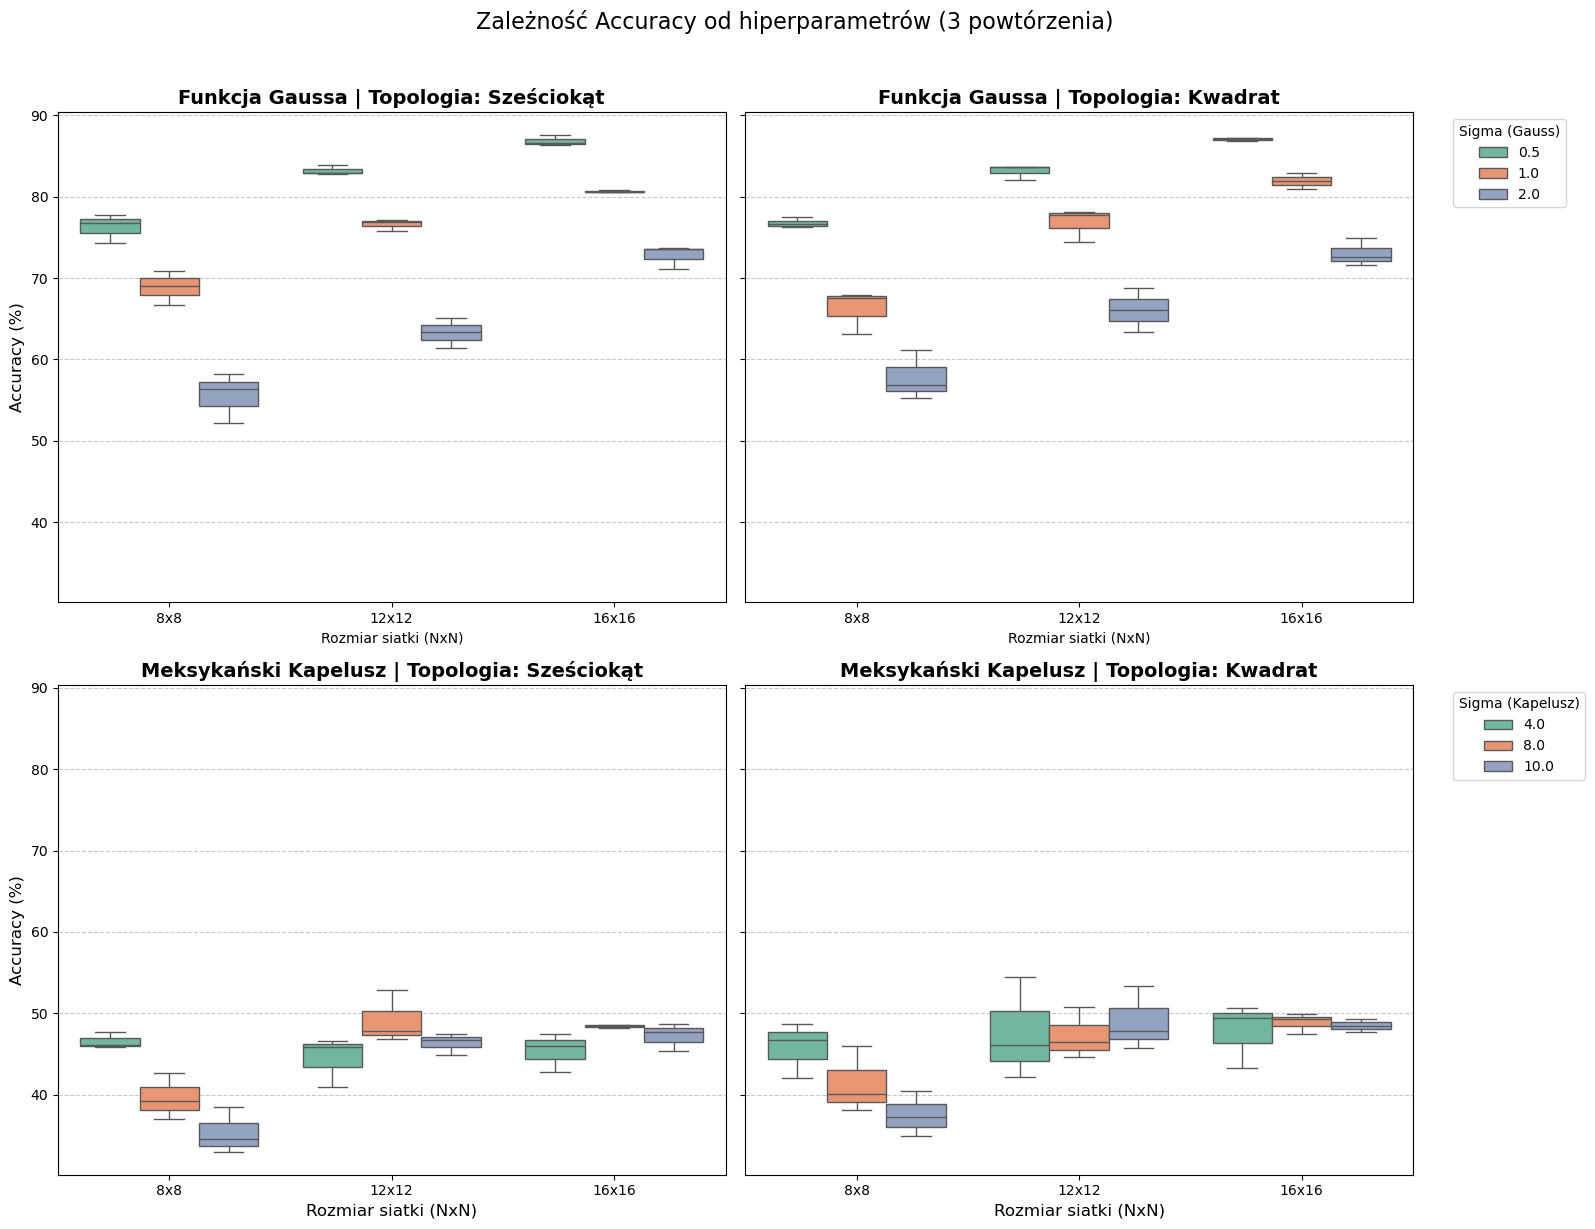

In [36]:
boxplot_porownanie_funkcji(mnist_full, N)

# Dane HAR

In [37]:
har_data = pd.read_csv("mio2/HAR/UCI HAR Dataset/UCI HAR Dataset/train/X_train.txt", sep=r'\s+', header=None)
y_etykiety = pd.read_csv("mio2/HAR/UCI HAR Dataset/UCI HAR Dataset/train/y_train.txt", sep=r'\s+', header=None)

har_data = har_data.to_numpy() 
y_etykiety = y_etykiety.to_numpy().astype(int) - 1 

liczba_klas = len(np.unique(y_etykiety))
y = to_one_hot(y_etykiety, liczba_klas)
n = har_data.shape[1]
ncols = har_data.shape[0]

In [38]:
N = 3
NM_lista = [5, 10, 15]
sigma_gauss = [0.5, 1, 2]
sigma_mexican = [4, 8, 10]
topologie = ['szesciokat', 'kwadrat']

In [39]:
har_full, har_full_avg = train_N(har_data, y_etykiety, n, NM_lista, sigma_gauss, sigma_mexican, topologie, N=N, epoki=10, wygaszanie=5)

display(har_full_avg)

Trening: 100%|██████████| 36/36 [15:23<00:00, 25.65s/model]


,Kombinacja,Rozmiar,Sigma,Funkcja,Topologia,Średnia Acc (%),Odchylenie Std
0,kwadrat | 15x15 | Sig=0.5 | funkcja_Gaussa,15x15,0.5,funkcja_Gaussa,kwadrat,90.770000,0.104403
1,szesciokat | 15x15 | Sig=0.5 | funkcja_Gaussa,15x15,0.5,funkcja_Gaussa,szesciokat,90.516667,0.392088
2,kwadrat | 10x10 | Sig=0.5 | funkcja_Gaussa,10x10,0.5,funkcja_Gaussa,kwadrat,87.386667,0.692917
3,kwadrat | 15x15 | Sig=1.0 | funkcja_Gaussa,15x15,1.0,funkcja_Gaussa,kwadrat,86.670000,0.497896
4,szesciokat | 15x15 | Sig=1.0 | funkcja_Gaussa,15x15,1.0,funkcja_Gaussa,szesciokat,86.650000,1.028397
5,szesciokat | 10x10 | Sig=0.5 | funkcja_Gaussa,10x10,0.5,funkcja_Gaussa,szesciokat,86.430000,0.542494
6,kwadrat | 15x15 | Sig=2.0 | funkcja_Gaussa,15x15,2.0,funkcja_Gaussa,kwadrat,83.826667,0.818372
7,szesciokat | 15x15 | Sig=2.0 | funkcja_Gaussa,15x15,2.0,funkcja_Gaussa,szesciokat,83.810000,0.565066
8,szesciokat | 10x10 | Sig=1.0 | funkcja_Gaussa,10x10,1.0,funkcja_Gaussa,szesciokat,83.330000,1.676097
9,kwadrat | 10x10 | Sig=1.0 | funkcja_Gaussa,10x10,1.0,funkcja_Gaussa,kwadrat,83.123333,0.493390


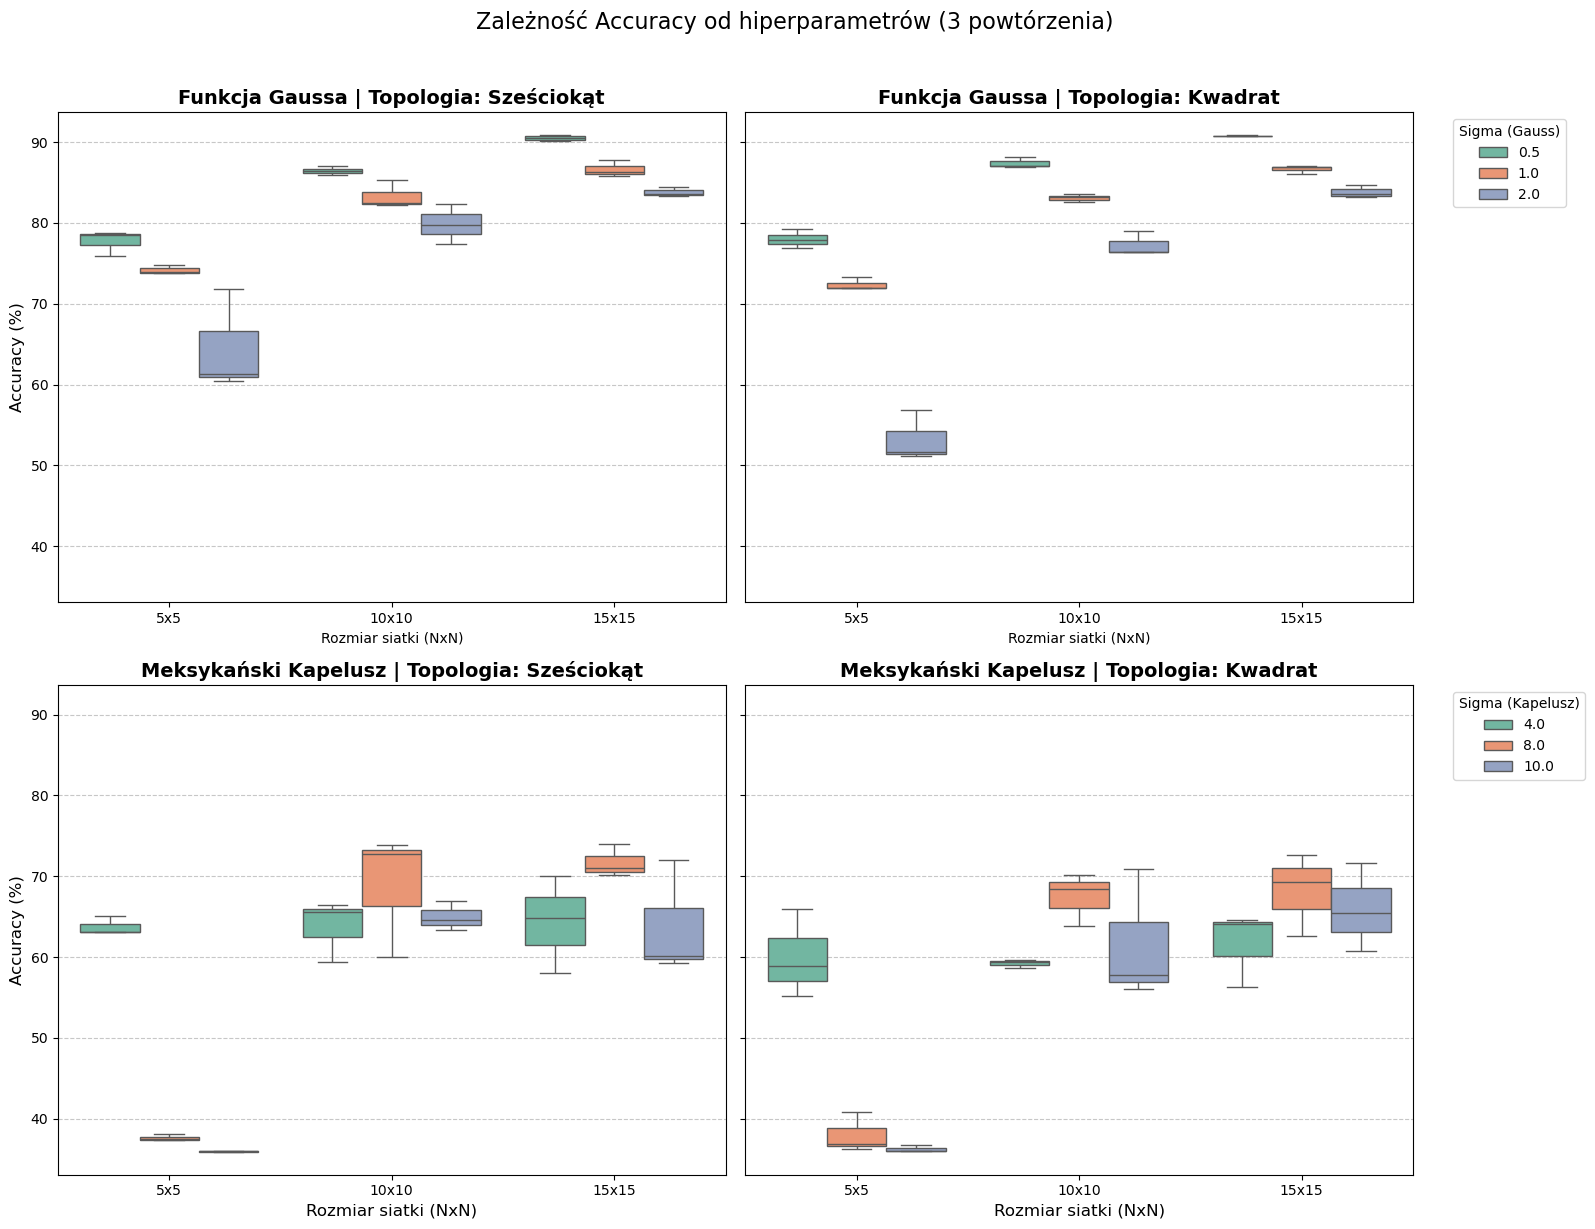

In [40]:
boxplot_porownanie_funkcji(har_full, N)